In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [32]:
df = pd.read_csv("C:/Users/HP/Desktop/Datasets/titanic.csv")

In [33]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [34]:
df.shape

(891, 12)

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [36]:
df.isnull().sum()


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [37]:
df.duplicated().sum()

np.int64(0)

Ages are grouped according to sex and passenger class to get better medians to fill the null values.

In [38]:
df['Age'] = df.groupby(['Sex', 'Pclass'])['Age'].transform(lambda ages: ages.fillna(ages.median()))

Null values for the Embarked column are filled with the mode.

In [44]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

The Cabin column is dropped and a new column CabinKnown which carries the value of availibilty of cabin information is introduced.

In [47]:
df['CabinKnown'] = df['Cabin'].notnull().map({
    True: 'Yes',
    False: 'No'
})

In [60]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.112424,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.304424,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,21.500000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,26.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,36.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


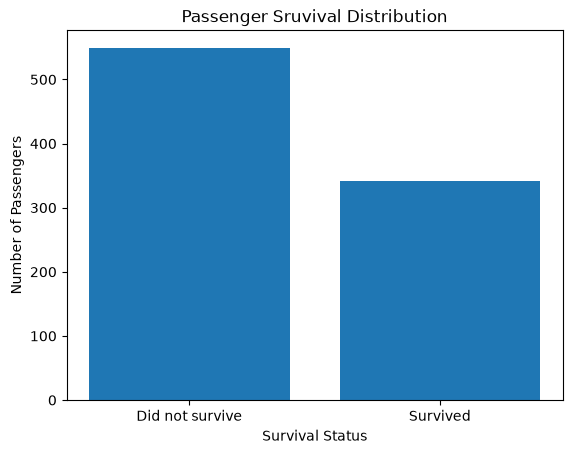

In [78]:
plt.bar(['Did not survive', 'Survived'], df['Survived'].value_counts())
plt.xlabel('Survival Status')
plt.ylabel('Number of Passengers')
plt.title('Passenger Sruvival Distribution')
plt.show()

In [75]:
sex_counts = df['Sex'].value_counts()

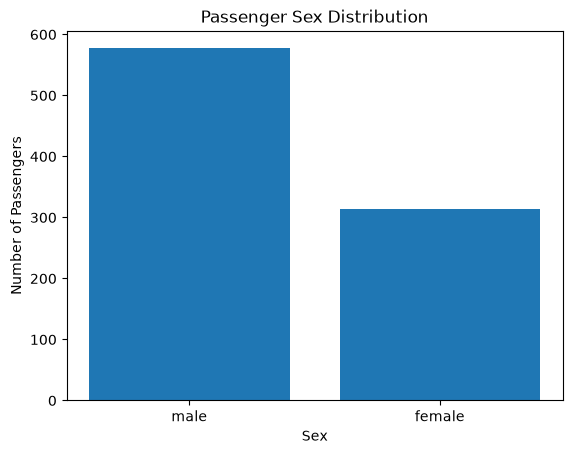

In [91]:
plt.bar(sex_counts.index, sex_counts.values)
plt.xlabel('Sex')
plt.ylabel('Number of Passengers')
plt.title('Passenger Sex Distribution')
plt.show()

In [81]:
p_class = df['Pclass'].value_counts()

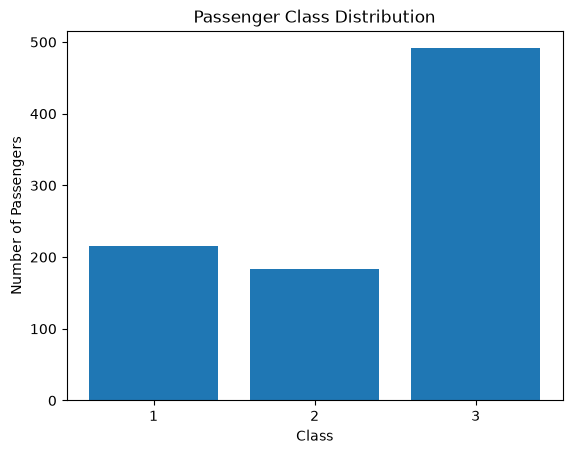

In [88]:
plt.bar(p_class.index, p_class.values)
plt.xlabel('Class')
plt.ylabel('Number of Passengers')
plt.title('Passenger Class Distribution')

plt.xticks([1, 2, 3])
plt.show()

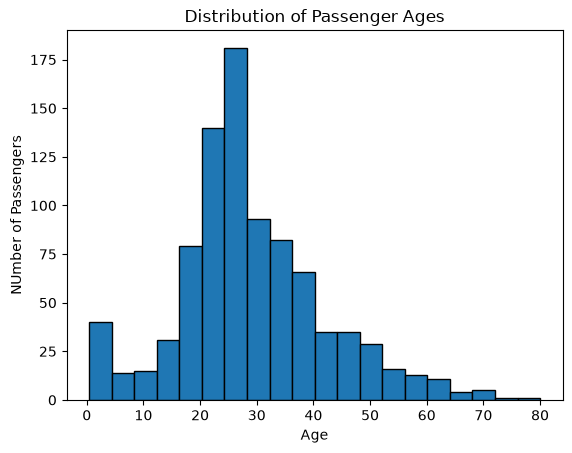

In [101]:
plt.hist(df['Age'], bins=20, edgecolor='black')

plt.xlabel('Age')
plt.ylabel('NUmber of Passengers')
plt.title('Distribution of Passenger Ages')


plt.show()

<Axes: >

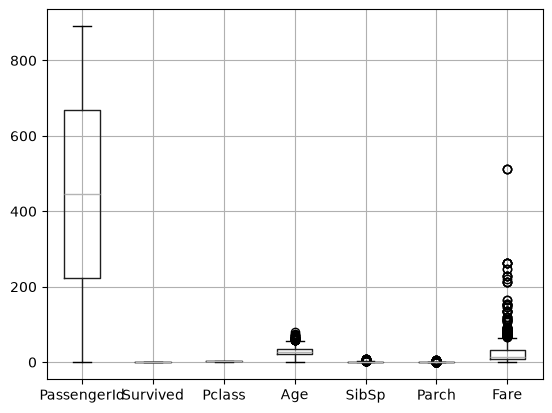

In [102]:
df.boxplot()

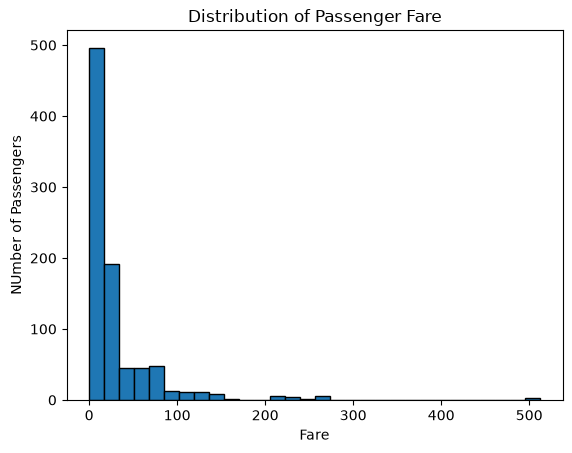

In [104]:
plt.hist(df['Fare'], bins=30, edgecolor='black')

plt.xlabel('Fare')
plt.ylabel('NUmber of Passengers')
plt.title('Distribution of Passenger Fare')


plt.show()

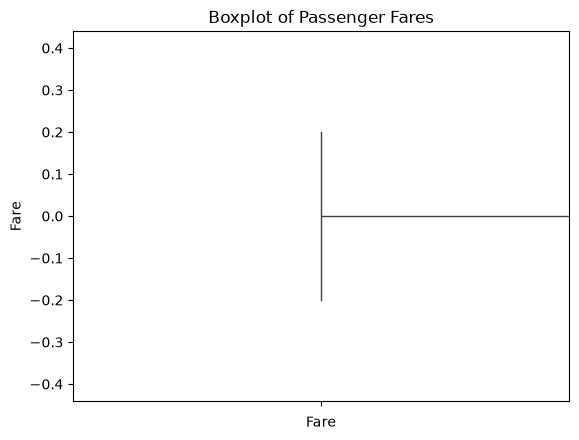

In [ ]:
plt.boxplot(df['Fare'], vert=False)

plt.xlabel('Fare')
plt.title('Boxplot of Passenger Fares')

plt.show()

In [111]:
sns.set_style('darkgrid')

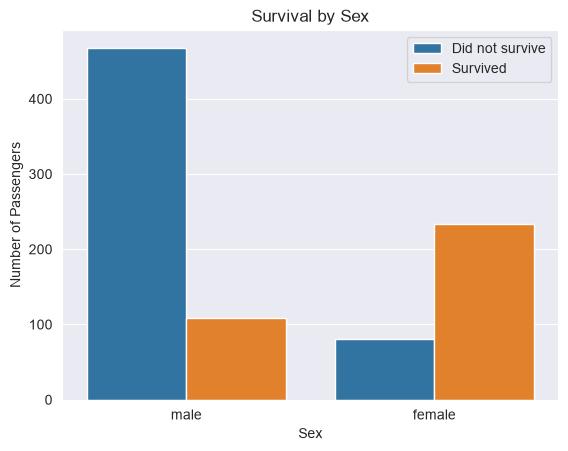

In [117]:
sns.countplot(data=df, x='Sex', hue='Survived')

plt.xlabel('Sex')
plt.ylabel('Number of Passengers')
plt.title('Survival by Sex')

plt.legend(labels=['Did not survive', 'Survived'])

plt.show()

Female passengers had a substantially higher survival rate than male passengers, while most male passengers did not survive.

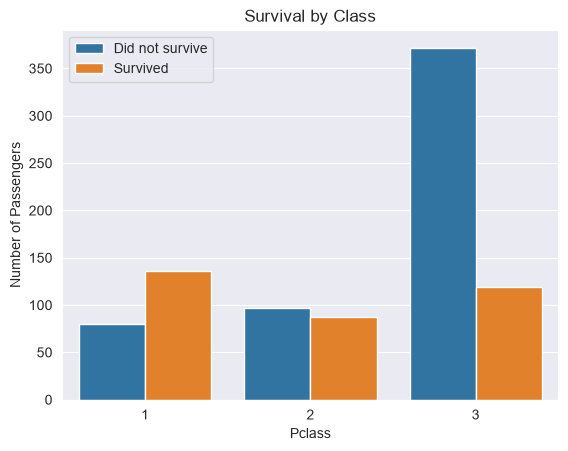

In [132]:
sns.countplot(data=df, x='Pclass', hue='Survived')

plt.xlabel('Pclass')
plt.ylabel('Number of Passengers')
plt.title('Survival by Class')

plt.legend(labels=['Did not survive', 'Survived'])

plt.show()

Passengers in 1st class had the highest survival rate, while 3rd-class passengers had the lowest survival rate.

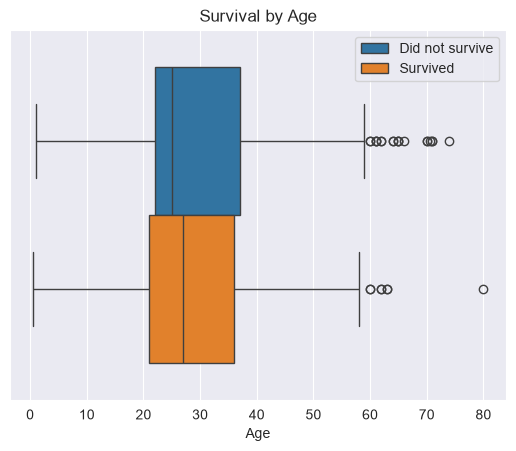

In [124]:
sns.boxplot(data=df, x='Age', hue='Survived')

plt.xlabel('Age')
plt.title('Survival by Age')

plt.legend(labels=['Did not survive', 'Survived'])

plt.show()

The age distribution of survivors and non-surviviors were broadly similar, with considerable overlap. Both groups contained some older-age outliers.

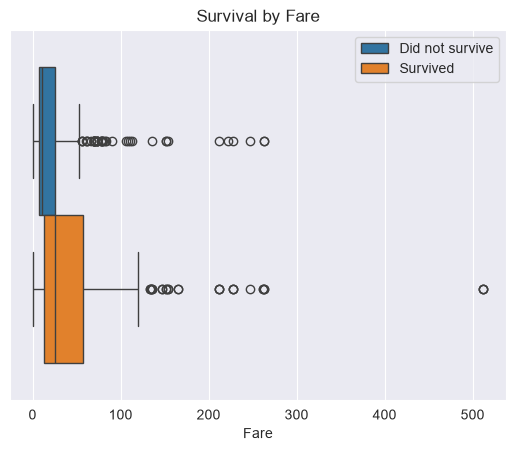

In [127]:
sns.boxplot(data=df, x='Fare', hue='Survived')

plt.xlabel('Fare')
plt.title('Survival by Fare')

plt.legend(labels=['Did not survive', 'Survived'])

plt.show()

Survivors generally had higher fares than non-survivors. The fare distribution was also right-skewed, with several unusually high fares.

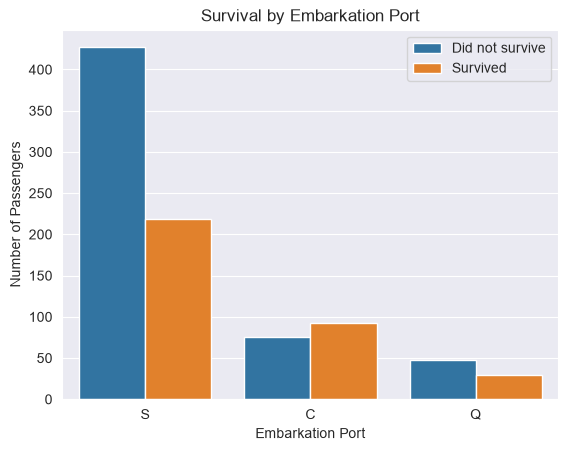

In [131]:
sns.countplot(data=df, x='Embarked', hue='Survived')

plt.xlabel('Embarkation Port')
plt.ylabel('Number of Passengers')
plt.title('Survival by Embarkation Port')

plt.legend(labels=['Did not survive', 'Survived'])

plt.show()

Survival varied across the three embarkation ports, with passengers who embarked fron C having a higher proprtion of survivors compared with the other ports.

In [134]:
df[["Age", "Survived", "Pclass"]].corr()

,Age,Survived,Pclass
Age,1.000000,-0.059579,-0.413583
Survived,-0.059579,1.000000,-0.338481
Pclass,-0.413583,-0.338481,1.000000


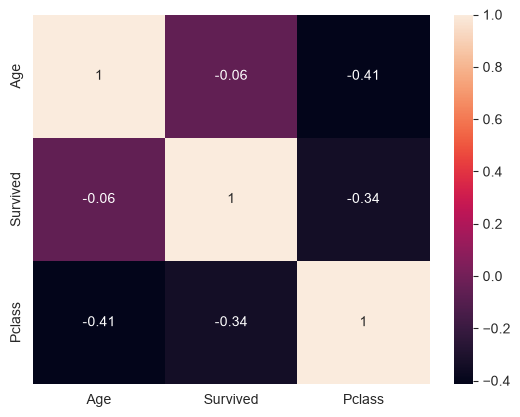

In [135]:
sns.heatmap(df[["Age", "Survived", "Pclass"]].corr(), annot= True)
plt.rcParams["figure.figsize"]= (10,7)